In [2]:
from graphviz import Digraph
from micrograd.nn import MLP

In [3]:
def draw_digraph(root):
    g = Digraph("computation graph", format="svg")
    g.attr(rankdir="LR")
    seen = set()

    def helper(v):
        if v in seen:
            return
        seen.add(v)
        uid = str(id(v))
        g.node(uid, label = "{ %s | data = %.4f | grad = %.4f}" % (v.label, v.data, v.grad), shape="record")
        if v._op:
            op_id = uid + v._op
            g.node(op_id, label=v._op)
            g.edge(op_id, uid) # op node -> curr node
            for c in v._children:
                g.edge(str(id(c)), op_id) # child node -> op node
                helper(c)

    helper(root)
    return g


In [4]:
# construct a 3-layer nn with 3-input feature
n = MLP(3, [4, 4, 1])

In [5]:
# build a small dataset
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [6]:
for k in range(10):

  ypred = [n(x) for x in xs]
  # calculate loss value using MSE
  loss = sum([(real - pred)**2 for real, pred in zip(ys, ypred)]) / len(ys)

  # gradient descend
  for p in n.params:
    p.grad = 0.0

  loss.backword()

  # gradient descend
  for p in n.params:
    p.data -= 0.001 * p.grad
  
  print(f"round {k}, loss value is {loss}")

round 0, loss value is Value(data=4.608340478762732)
round 1, loss value is Value(data=4.213248314529957)
round 2, loss value is Value(data=3.871354660467437)
round 3, loss value is Value(data=3.573481951362639)
round 4, loss value is Value(data=3.312368913636466)
round 5, loss value is Value(data=3.0822044087762817)
round 6, loss value is Value(data=2.878289589115104)
round 7, loss value is Value(data=2.696789251330361)
round 8, loss value is Value(data=2.534546268307926)
round 9, loss value is Value(data=2.388941327416997)


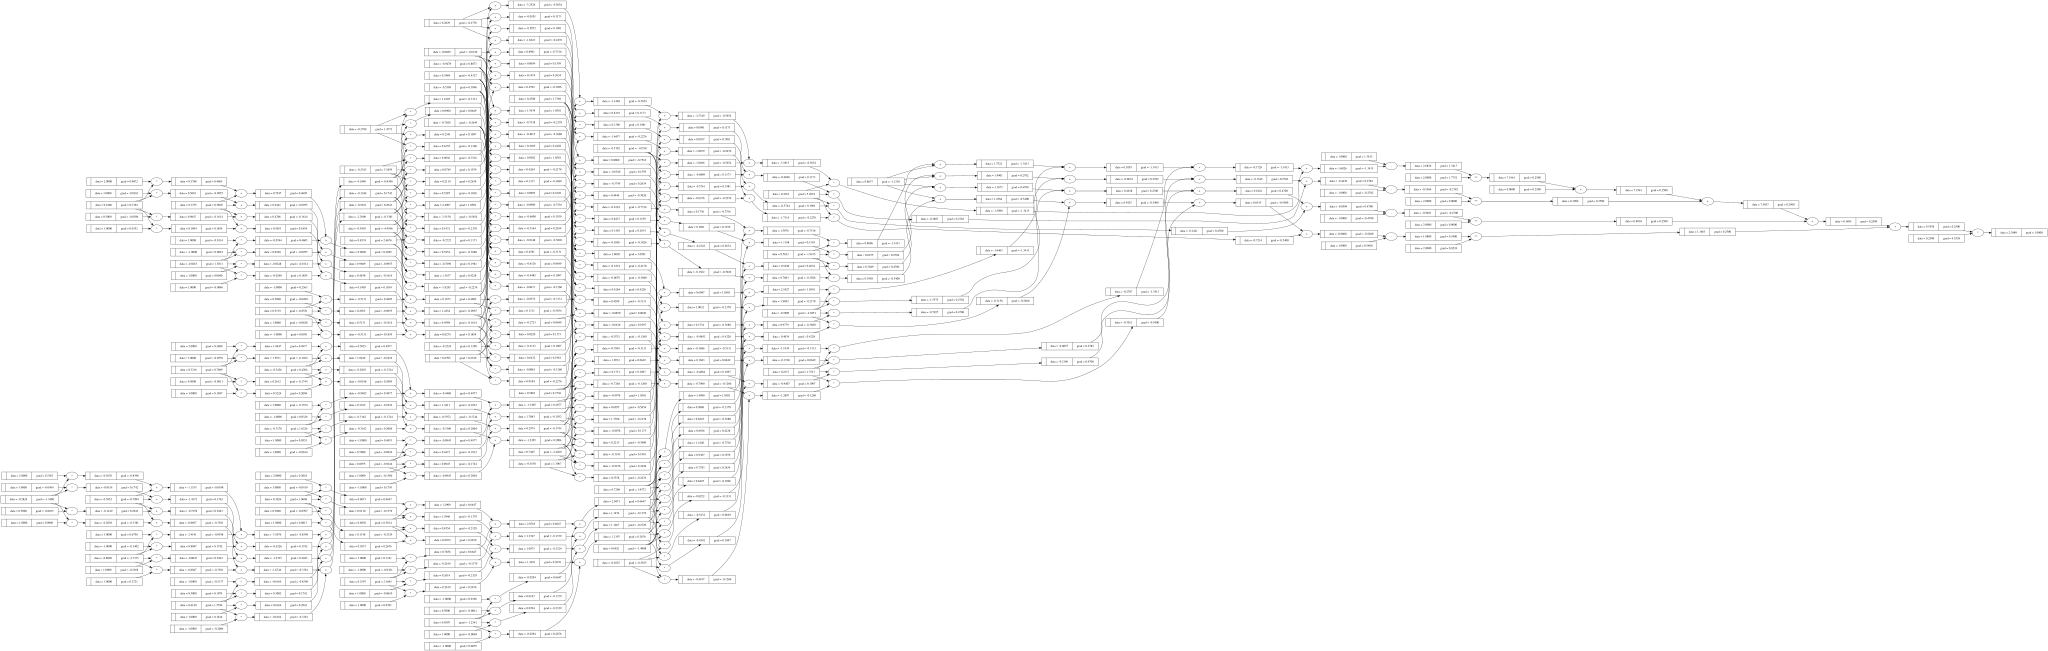

In [7]:
draw_digraph(loss)